In [13]:
from qiskit import *
from math import log2

In [25]:
#point arithmetic

Point = tuple[int, int]

def mod_inverse(n: int, p: int) -> int:
    """Modular inverse via Fermat's little theorem (p must be prime)."""
    return pow(n, p - 2, p)


def point_add(P: Point, Q: Point, a: int, p: int) -> Point:
    """
    Add two points P and Q on the elliptic curve y² = x³ + ax + b (mod p).
    Returns the resulting point, or (0, 0) if the result is the point at infinity.
    """
    # Identidade: se um dos pontos for o infinito (0, 0), retorna o outro
    if P == (0, 0):
        return Q
    if Q == (0, 0):
        return P

    x1, y1 = P
    x2, y2 = Q

    # P + (-P) = infinity
    if x1 == x2 and (y1 + y2) % p == 0:
        return (0, 0)

    if P == Q:
        # Point doubling
        if y1 == 0:
            return (0, 0)
        lam = (3 * x1 * x1 + a) * mod_inverse(2 * y1, p) % p
    else:
        # Point addition
        lam = (y2 - y1) * mod_inverse(x2 - x1, p) % p

    x3 = (lam * lam - x1 - x2) % p
    y3 = (lam * (x1 - x3) - y1) % p
    return (x3, y3)


def scalar_mult(k: int, P: Point, a: int, p: int) -> Point:
    """Compute k·P using the double-and-add algorithm."""
    # O elemento neutro (identidade) agora é (0, 0)
    result: Point = (0, 0)  
    addend = P
    
    while k:
        if k & 1:
            result = point_add(result, addend, a, p)
        addend = point_add(addend, addend, a, p)
        k >>= 1
        
    return result

def is_on_curve(P: Point, curve_params: tuple[int, int, int]) -> bool:
    """
    Verifica se um ponto P(x, y) pertence à curva elíptica y² = x³ + ax + b (mod p).
    Recebe o Ponto e uma tupla contendo os parâmetros (a, b, p).
    """
    a, b, p = curve_params
    
    if P == (0, 0):
        return True
        
    x, y = P
    
    lhs = (y * y) % p
    rhs = (x * x * x + a * x + b) % p
    
    return lhs == rhs

def curve_points(a: int, b: int, p: int) -> list[Point]:
    """Enumerate all affine points on the curve, including the point at infinity in (0, 0)."""
    points: list[Point] = [(0, 0)]
    for x in range(p):
        rhs = (x * x * x + a * x + b) % p
        for y in range(p):
            if (y * y) % p == rhs:
                points.append((x, y))
    return points

def point_inverse(P: Point, p: int) -> Point:
    """Retorna o inverso de um ponto na curva elíptica."""
    if P == (0, 0):
        return (0, 0)

    x, y = P
    return (x, (-y) % p)

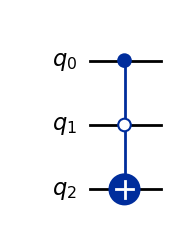

In [3]:
qc = QuantumCircuit(3)

qc.ccx(0,1,2, ctrl_state="01")
qc.draw("mpl")

In [11]:
def get_bit_string(a: int, n: int) -> str:
    return bin(a)[2:].zfill(n)

In [23]:
def set_point(Q: Point, R: Point, n: int) -> QuantumCircuit:
    """
    assumes register in state Q, sets it to R
    """
    reg_x = QuantumRegister(n, "x")
    reg_y = QuantumRegister(n, "y")
    quantum_circuit = QuantumCircuit(reg_x, reg_y)

    for i in range(n):
        if((R[0] >> i) & 1) != ((Q[0] >> i) & 1):
            quantum_circuit.x(reg_x[i])
        if((R[1] >> i) & 1) != ((Q[1] >> i) & 1):
            quantum_circuit.x(reg_y[i])  

    return quantum_circuit

In [24]:
def sum_case_2(Q: Point, a: int, p: int) -> QuantumCircuit:
    """
    eliptic curve point sum case 2: P = Q
    """
    n = int(log2(p)) + 1
    reg_x = QuantumRegister(n, "x")
    reg_y = QuantumRegister(n, "y")
    reg_flag = QuantumRegister(1, "flag")
    quantum_circuit = QuantumCircuit(reg_x, reg_y, reg_flag)

    R = scalar_mult(2, Q, a, p)
    c_string =  get_bit_string(Q[1], n) + get_bit_string(Q[0], n)
    c_string_2 = get_bit_string(R[1], n) + get_bit_string(R[0], n) 

    quantum_circuit.mcx(reg_x[:] + reg_y[:], reg_flag[0], ctrl_state=c_string)
    quantum_circuit.append(set_point(Q, R, n).control(1), reg_flag[:] + reg_x[:] + reg_y[:])
    quantum_circuit.mcx(reg_x[:] + reg_y[:], reg_flag[0], ctrl_state=c_string_2)

    return quantum_circuit

In [27]:
def sum_case_3(Q: Point, a: int, p: int, inf: Point = [0,0]) -> QuantumCircuit:
    """
    eliptic curve point sum case 3: P = -Q
    """
    n = int(log2(p)) + 1
    reg_x = QuantumRegister(n, "x")
    reg_y = QuantumRegister(n, "y")
    reg_flag = QuantumRegister(1, "flag")
    quantum_circuit = QuantumCircuit(reg_x, reg_y, reg_flag)

    R = point_inverse(Q, p)

    c_string =  get_bit_string(R[1], n) + get_bit_string(R[0], n)
    c_string_2 = get_bit_string(inf[1], n) + get_bit_string(inf[0], n)

    quantum_circuit.mcx(reg_x[:] + reg_y[:], reg_flag[0], ctrl_state=c_string)
    quantum_circuit.append(set_point(R, inf, n).control(1), reg_flag[:] + reg_x[:] + reg_y[:])
    quantum_circuit.mcx(reg_x[:] + reg_y[:], reg_flag[0], ctrl_state=c_string_2)

    return quantum_circuit

In [26]:
def sum_case_4(Q: Point, a: int, p: int, inf: Point = [0,0]) -> QuantumCircuit:
    """
    eliptic curve point sum case 4: P = O
    """
    n = int(log2(p)) + 1
    reg_x = QuantumRegister(n, "x")
    reg_y = QuantumRegister(n, "y")
    reg_flag = QuantumRegister(1, "flag")
    quantum_circuit = QuantumCircuit(reg_x, reg_y, reg_flag)

    c_string =  get_bit_string(inf[1], n) + get_bit_string(inf[0], n)
    c_string_2 = get_bit_string(Q[1], n) + get_bit_string(Q[0], n)

    quantum_circuit.mcx(reg_x[:] + reg_y[:], reg_flag[0], ctrl_state=c_string)
    quantum_circuit.append(set_point(inf, Q, n).control(1), reg_flag[:] + reg_x[:] + reg_y[:])
    quantum_circuit.mcx(reg_x[:] + reg_y[:], reg_flag[0], ctrl_state=c_string_2)

    return quantum_circuit